In [104]:
from langgraph.graph import StateGraph, START,END
from langchain_google_genai import ChatGoogleGenerativeAI
from typing import TypedDict,Annotated
from dotenv import load_dotenv
from pydantic import BaseModel, Field
import operator

In [105]:
load_dotenv()

True

In [106]:
model=ChatGoogleGenerativeAI(model="gemini-3.8-flash")


In [107]:
class EvaluationSchema(BaseModel):
    feedback:str =Field(description='Detailed Feedback For The Essay')
    score:int =Field(description='Score out of 10' ,ge=0, le=10)

In [108]:
Structured_Model=model.with_structured_output(EvaluationSchema)


In [109]:
essay="""
Gilgit-Baltistan: The Northern Jewel of Pakistan

Gilgit-Baltistan, located in the extreme north of Pakistan, is a breathtaking region known for its towering mountains, vast glaciers, and rich cultural heritage. Spanning over 72,000 square kilometers, it shares borders with China, Afghanistan, and India, making it one of the most strategically important territories in South Asia. Often described as a paradise on Earth, Gilgit-Baltistan captivates travelers, mountaineers, and historians alike with its natural beauty and timeless traditions.

The geography of Gilgit-Baltistan is truly unmatched anywhere in the world. Near the town of Jaglot, three of the planet's greatest mountain ranges—the Karakoram, the Himalayas, and the Hindu Kush—converge at a single junction. The region boasts five of the world's fourteen peaks that exceed 8,000 meters in height, including K2, the second-highest mountain on Earth, and Nanga Parbat. In addition to its rocky giants, Gilgit-Baltistan contains the largest network of glaciers outside the polar regions, such as the Baltoro and Biafo glaciers. The seasonal melting of these massive ice sheets feeds the Indus River, serving as the primary water lifeline for the entire agricultural and economic system of Pakistan.

Historically, Gilgit-Baltistan served as a vital corridor along the ancient Silk Road. For centuries, merchants, scholars, and Buddhist monks traversed its narrow mountain passes, exchanging goods, art, and ideas between China and the Indian subcontinent. Ancient petroglyphs, rock carvings, and stupas scattered throughout Gilgit, Hunza, and Skardu stand as silent witnesses to this diverse past. During the nineteenth century, the region came under the control of the Dogra rulers of Kashmir and later became a focal point of geopolitical rivalry during the British colonial era. Following the partition of British India in 1947, the local population rose up to liberate themselves from Dogra rule and acceded to Pakistan, eventually establishing the region's current status as a self-governing administrative territory.

Beyond its dramatic landscapes, the true wealth of Gilgit-Baltistan lies in its resilient and welcoming people. Despite the challenges of harsh winters and rugged terrain, the region is home to a vibrant mix of ethnic and linguistic communities, including the Shina, Balti, Burusho, and Wakhi peoples. Hospitality is deeply woven into the local way of life, and visitors are greeted with genuine warmth. Traditional music, folk dances, and seasonal festivals keep ancient customs alive. Sports also play a central role in community life, particularly freestyle polo, which has been played in these valleys for centuries. Every summer, the Shandur Pass—the highest polo ground in the world—hosts an iconic tournament that draws crowds from across the country and around the globe.

In the modern era, Gilgit-Baltistan has emerged as the premier hub for tourism and regional connectivity in Pakistan. Destinations like Hunza Valley, Skardu, Fairy Meadows, and the high-altitude Deosai Plains attract hundreds of thousands of visitors each year. Connecting these remote valleys to the rest of the world is the Karakoram Highway, an engineering marvel carved through sheer rock faces that links Pakistan with China. Through this highway, Gilgit-Baltistan forms the northern gateway of the China-Pakistan Economic Corridor (CPEC), positioning the region at the center of future trade and economic growth.

In conclusion, Gilgit-Baltistan is far more than a scenic tourist destination. It is an ecological treasure, a historical crossroads of civilizations, and a vital pillar of Pakistan's geography and economy. Balancing modern infrastructure and tourism with environmental conservation will ensure that the pristine beauty and unique heritage of Gilgit-Baltistan remain preserved for generations to come."""

In [ ]:
prompt=f"Evaluate the language quality of the following essay and provide a feedback and assign a score out of 10 {essay}"
Structured_Model.invoke(prompt).score

In [ ]:
class CssState(TypedDict):
    essay:str
    language_feedback:str
    clarity_feedback:str
    analysis_feedback:str
    overall_feedback:str
    individual_score:Annotated[list[int],operator.add]
    average_score:float
    

In [ ]:
def Evaluate_language(state:CssState):
  prompt=f"Evaluate the language quality of the following essay and provide a feedback and assign a score out of 10 {state['essay']}"
  output=Structured_Model.invoke(prompt)
  return {"language_feedback" : output.feedback, "individual_score":[output.score]}


In [ ]:
def Evaluate_clarity(state:CssState):
  prompt=f"Evaluate the clarity of language of the following essay and provide a feedback and assign a score out of 10 {state['essay']}"
  output=Structured_Model.invoke(prompt)
  return {"clarity_feedback" : output.feedback, "individual_score":[output.score]}

In [ ]:
def Evaluate_analysis(state:CssState):
  prompt=f"Evaluate the depth of analysis of the following essay and provide a feedback and assign a score out of 10 {state['essay']}"
  output=Structured_Model.invoke(prompt)
  return {"analysis_feedback" : output.feedback, "individual_score":[output.score]}

In [ ]:
def Overall_feedback(state:CssState):
  prompt=f"Based on the following feedbacks Language Feedback--{state['language_feedback']} Clarity Feedback--{state['clarity_feedback']} Analysis Feedback--{state['analysis_feedback']} provide a summarized feedback"
  output=model.invoke(prompt).content
  scores = state["individual_score"]

  if not scores:
      raise ValueError("No individual scores were generated")

  average_score = sum(scores) / len(scores)
  return {"overall_feedback" : output, "average_score":average_score}

In [ ]:
graph=StateGraph(CssState)
graph.add_node('evaluate_language',Evaluate_language)
graph.add_node('evaluate_clarity',Evaluate_clarity)
graph.add_node('evaluate_analysis',Evaluate_analysis)
graph.add_node('final_feedback',Overall_feedback)

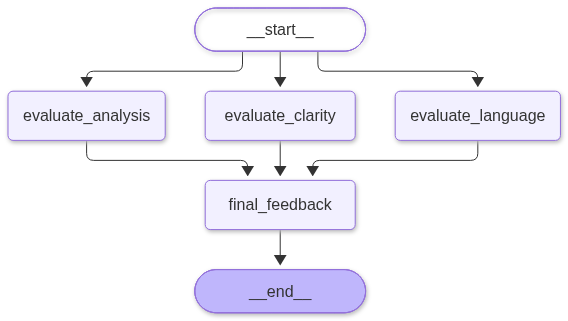

In [ ]:
graph.add_edge(START,'evaluate_language')
graph.add_edge(START,'evaluate_clarity')
graph.add_edge(START,'evaluate_analysis')
graph.add_edge('evaluate_language','final_feedback')
graph.add_edge('evaluate_clarity','final_feedback')
graph.add_edge('evaluate_analysis','final_feedback')
graph.add_edge('final_feedback',END)
workflow=graph.compile()
workflow

In [ ]:
initial_state={"essay":essay}
output=workflow.invoke(initial_state)
output

ValueError: No individual scores were generated